# Electronic health records

Electronic health records follow a patient through time, with laboratory values, vital signs and treatments recorded
day by day. A blood sample for single-cell sequencing is a snapshot taken on one of those days. Relating the two
means asking what the record said on the day the blood was drawn, and that question involves all three levels of a
DonorData: the patient with the record, the sample with its collection day, and the cells.

[ehrdata](https://ehrdata.readthedocs.io) stores records as an `EHRData`, an AnnData with a time axis: patients by
variables by time points. A DonorData accepts it as `D`, keeps the time series aligned when patients are selected,
and writes it to disk together with the samples and cells.

The cohort below is simulated so that the tutorial runs in seconds without access restrictions. Sixty hospitalized
patients have daily laboratory values over two weeks, and blood was sequenced on day 1 and, for most patients, again
on day 7. Monocytes expand and lymphocytes contract with the inflammation of the day, and inflamed monocytes express
the alarmins S100A8 and S100A9.

In [1]:
import anndata as ad
import ehrdata as ed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from donordata import DonorData, read_dd

rng = np.random.default_rng(0)

## The health record

Every patient has an age, a sex and a clinical course, either recovering or worsening. C-reactive protein (CRP),
lymphocyte counts and interleukin 6 (IL6) are recorded on 15 days. IL6 is measured only every other day, as is common
for less routine tests, so the record has gaps.

In [2]:
n_patients, days = 60, np.arange(15)
patients = pd.DataFrame(
    {
        "age": rng.integers(25, 85, n_patients),
        "sex": pd.Categorical(rng.choice(["female", "male"], n_patients)),
        "course": pd.Categorical(rng.choice(["recovering", "worsening"], n_patients, p=[0.6, 0.4])),
    },
    index=pd.Index([f"P{i:02d}" for i in range(n_patients)], name="patient_id"),
)

worsening = (patients["course"] == "worsening").to_numpy()
peak = rng.uniform(40, 120, n_patients)
decay = np.where(worsening, rng.uniform(-0.04, 0.02, n_patients), rng.uniform(0.15, 0.3, n_patients))
crp = peak[:, None] * np.exp(-decay[:, None] * days[None, :]) * rng.lognormal(0, 0.15, (n_patients, days.size))
lymphocytes = np.clip(2.2 - 0.6 * np.log1p(crp / 20) + rng.normal(0, 0.15, crp.shape), 0.2, None)
il6 = 3 + 0.5 * crp * rng.lognormal(0, 0.3, crp.shape)
il6[:, days % 2 == 1] = np.nan

labs = np.stack([crp, lymphocytes, il6], axis=1)
variables = pd.DataFrame({"unit": ["mg/L", "10^9/L", "pg/mL"]}, index=["CRP", "lymphocytes", "IL6"])
timepoints = pd.DataFrame({"day": days}, index=[f"day_{d}" for d in days])

ehr = ed.EHRData(X=labs[:, :, 0], obs=patients, var=variables, layers={"tem_data": labs}, tem=timepoints)
ehr

EHRData object with n_obs × n_vars × n_t = 60 × 3 × 15
    obs: 'age', 'sex', 'course'
    var: 'unit'
    tem: 'day_0', 'day_1', 'day_2', 'day_3', 'day_4', 'day_5', 'day_6', 'day_7', 'day_8', 'day_9', 'day_10', 'day_11', 'day_12', 'day_13', 'day_14'
    layers: 'tem_data'
    shape of .X: (60, 3)
    shape of .tem_data: (60, 3, 15)

`X` holds the values at admission and the layer `tem_data` the full time series.

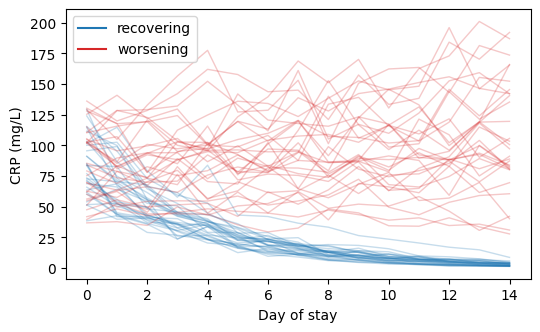

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for course, color in [("recovering", "tab:blue"), ("worsening", "tab:red")]:
    member = (patients["course"] == course).to_numpy()
    ax.plot(days, crp[member].T, color=color, alpha=0.25, lw=1)
    ax.plot([], [], color=color, label=course)
ax.set_xlabel("Day of stay")
ax.set_ylabel("CRP (mg/L)")
ax.legend()
plt.show()

## Blood draws and cells

Blood was sequenced on day 1 and, for 45 patients, again on day 7. Each draw yields 300 cells. The cell type
composition, which also differs between patients, and the alarmin expression of monocytes follow the CRP of the day
of the draw, which is how the simulation links the record to the cells.

In [4]:
draws = [(p, 1) for p in patients.index] + [(p, 7) for p in rng.choice(patients.index, 45, replace=False)]
samples = pd.DataFrame(
    {"patient_id": [p for p, _ in draws], "day": [d for _, d in draws]},
    index=pd.Index([f"{p}_day{d}" for p, d in draws], name="sample_id"),
)

cell_types = np.array(["Monocyte", "CD4 T", "CD8 T", "B", "NK"])
markers = {
    "Monocyte": ["CD14", "LYZ", "FCN1"],
    "CD4 T": ["CD3E", "IL7R", "CD4"],
    "CD8 T": ["CD3E", "CD8A", "GZMK"],
    "B": ["MS4A1", "CD79A", "CD19"],
    "NK": ["NKG7", "GNLY", "KLRD1"],
}
genes = sorted({g for names in markers.values() for g in names} | {"S100A8", "S100A9", "ACTB", "MALAT1"})

baseline = rng.normal(0, 0.35, (n_patients, cell_types.size))
blocks = []
for sample, (patient, day) in zip(samples.index, draws, strict=True):
    position = patients.index.get_loc(patient)
    inflammation = np.log1p(crp[position, day] / 20)
    shift = np.array([0.9, -0.5, -0.5, -0.3, 0.0]) * inflammation
    logits = baseline[position] + np.array([0.0, 0.8, 0.2, -0.4, -0.2]) + shift
    types = rng.choice(cell_types, 300, p=np.exp(logits) / np.exp(logits).sum())
    rate = np.full((300, len(genes)), 0.2)
    rate[:, genes.index("ACTB")] = rate[:, genes.index("MALAT1")] = 5.0
    for cell_type, names in markers.items():
        rows = types == cell_type
        rate[np.ix_(rows, [genes.index(g) for g in names])] = 4.0
    monocytes = types == "Monocyte"
    rate[np.ix_(monocytes, [genes.index("S100A8"), genes.index("S100A9")])] = 1.0 + 3.0 * inflammation
    blocks.append(pd.DataFrame(rng.poisson(rate), columns=genes).assign(sample_id=sample, cell_type=types))

table = pd.concat(blocks, ignore_index=True)
table.index = [f"cell_{i}" for i in range(len(table))]
counts = table[genes].to_numpy(dtype=np.float32)
cells = ad.AnnData(
    X=np.log1p(counts / counts.sum(axis=1, keepdims=True) * 1e3),
    obs=table[["sample_id", "cell_type"]].astype("category"),
    var=pd.DataFrame(index=genes),
    layers={"counts": counts},
)
cells

AnnData object with n_obs × n_vars = 31500 × 18
    obs: 'sample_id', 'cell_type'
    layers: 'counts'

## One object for record, samples and cells

The record becomes `D`, the draws `S` and the cells `C`. The panel of `D` shows the time axis next to the usual
AnnData slots.

In [5]:
dd = DonorData(D=ehr, S=samples, C=cells, donor_id="patient_id", sample_id="sample_id")
dd

╔═ DonorData(n_donors=60, n_samples=105, n_cells=31,500) ══════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..2 per   ┃ C (cells, 300..300 per ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ sample)                ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ EHRData object with    │ DataFrame with 105     │ View of AnnData object │ ║
║ │ n_obs × n_vars = 60 ×  │ samples × 2 columns    │ with n_obs × n_vars =  │ ║
║ │ 3                      │                        │ 31,500 × 18            │ ║
║ │     tem: 15 timepoints │     columns:           │     obs: 'sample_id',  │ ║
║ │                        │ 'patient_id', 'day'    │ 'cell_type'            │ ║
║ │     obs: 'age', 'sex', │                        │     layers: 'counts'   │ ║
║ │ 'course'               │                        │                        │ ║
║ │     var: 'unit'        │                        │                        │ ║
║ │     layers: 'tem_data' │                        │                        │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='patient_id', sample_id='sample_id' ═══════════════════════════════╝

Selecting patients selects their records, time series included, together with their draws and cells.

In [6]:
older = dd.filter_donors("age >= 60")
print(type(older.D).__name__, older.D.layers["tem_data"].shape, older.n_samples, older.n_cells)

EHRData (27, 3, 15) 48 14400


## The record on the day of the draw

For each blood sample we look up the CRP on the day it was drawn. Every sample has a patient and a day, so the
matching value is one indexing step into the time series. For IL6, which has
gaps, we carry the last measurement forward, a common convention for laboratory values.

In [7]:
series = pd.DataFrame(dd.D.layers["tem_data"].reshape(-1, dd.D.n_t)).ffill(axis=1).to_numpy()
series = series.reshape(dd.D.layers["tem_data"].shape)
day_of_draw = pd.Index(dd.D.tem["day"]).get_indexer(dd.S["day"])
at_draw = series[dd.sample_donor_codes, :, day_of_draw]
for position, variable in enumerate(dd.D.var_names):
    dd.S[f"{variable}_at_draw"] = at_draw[:, position]
dd.S.head()

,patient_id,day,CRP_at_draw,lymphocytes_at_draw,IL6_at_draw
sample_id,,,,,
P00_day1,P00,1,54.141701,1.524512,65.548344
P01_day1,P01,1,51.719021,1.361254,33.483482
P02_day1,P02,1,95.318308,1.061497,42.527119
P02_day7,P02,7,19.497227,1.928063,10.356089
P03_day1,P03,1,70.496261,1.025278,30.133427


`get_df` now puts the admission values from `X`, the values on the day of the draw from the sample table and the cell
type composition side by side, one row per sample.

In [8]:
dd.composition("cell_type", clr=True, level="sample")
per_sample = dd.get_df(["CRP", "CRP_at_draw", "day", "course", "cell_type_clr"], level="sample")
per_sample.head()

,CRP,CRP_at_draw,day,course,B,CD4 T,CD8 T,Monocyte,NK
sample_id,,,,,,,,,
P00_day1,73.490100,54.141701,1,recovering,-0.572509,0.500624,-0.338108,1.102646,-0.692653
P01_day1,71.536577,51.719021,1,recovering,-0.639780,0.043111,-0.681453,1.214603,0.063519
P02_day1,115.299274,95.318308,1,recovering,-0.731172,0.071174,-0.839386,1.499669,-0.000285
P02_day7,115.299274,19.497227,7,recovering,-0.223768,0.562598,-0.719384,0.475110,-0.094556
P03_day1,72.712479,70.496261,1,recovering,-0.924734,0.493649,-0.563720,2.010510,-1.015705


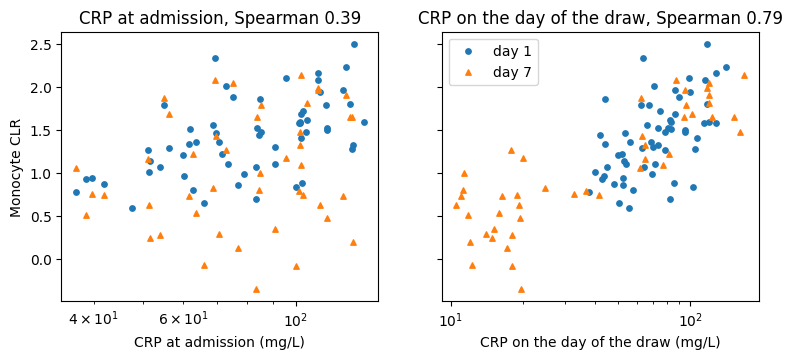

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, column, label in [(axes[0], "CRP", "CRP at admission"), (axes[1], "CRP_at_draw", "CRP on the day of the draw")]:
    for day, marker in [(1, "o"), (7, "^")]:
        rows = per_sample["day"] == day
        ax.scatter(
            per_sample.loc[rows, column], per_sample.loc[rows, "Monocyte"], s=15, marker=marker, label=f"day {day}"
        )
    rho = per_sample[[column, "Monocyte"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{label}, Spearman {rho:.2f}")
    ax.set_xscale("log")
    ax.set_xlabel(f"{label} (mg/L)")
axes[0].set_ylabel("Monocyte CLR")
axes[1].legend()
plt.show()

The monocyte share follows the CRP of the day of the draw, with a rank correlation of 0.79 against 0.39 for the CRP at
admission. The difference comes from the day 7 samples of recovering patients. Their admission CRP was high, but by
the day of the draw the inflammation had resolved and their monocytes were back at low levels.

## Cells next to the record

The same alignment reaches the cells. Monocyte pseudobulk profiles per sample carry the sample table, now with the
CRP of the draw, together with the patient table, so expression can be plotted against the record directly.

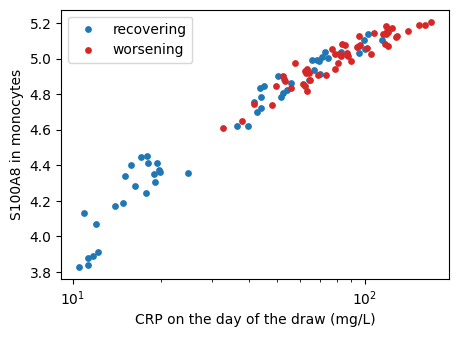

In [10]:
monocytes = dd.filter_cells("cell_type == 'Monocyte'").pseudobulk(func="mean", level="sample")
fig, ax = plt.subplots(figsize=(5, 3.5))
for course, color in [("recovering", "tab:blue"), ("worsening", "tab:red")]:
    rows = (monocytes.obs["course"] == course).to_numpy()
    ax.scatter(
        monocytes.obs.loc[rows, "CRP_at_draw"], monocytes[rows, "S100A8"].X.ravel(), s=15, color=color, label=course
    )
ax.set_xscale("log")
ax.set_xlabel("CRP on the day of the draw (mg/L)")
ax.set_ylabel("S100A8 in monocytes")
ax.legend()
plt.show()

S100A8 expression in monocytes rises with the CRP of the day of the draw. The lowest values all come from recovering
patients on day 7, while worsening patients stay inflamed and keep a high alarmin expression.

## Record and cells in one batch

For models that combine the record with the cells, `MILDataset` yields the admission values of `D.X` as patient
features next to a bag of cells and the label of every patient.

In [11]:
from torch.utils.data import DataLoader

from donordata.ml import MILDataset, mil_collate_fn

dataset = MILDataset(dd, donor_labels_key="course", n_cells=200, random_state=0)
batch = next(iter(DataLoader(dataset, batch_size=8, collate_fn=mil_collate_fn)))
batch["donor_x"].shape, batch["cell_x"].shape, dataset.encodings["course"]

(torch.Size([8, 3]), torch.Size([8, 200, 18]), ['recovering', 'worsening'])

## Saving

The record is written with its time axis and its three dimensional layers, next to the draws and cells, and read
back as an `EHRData`.

In [12]:
dd.write_dd("data/ehr_cohort.dd.h5")
loaded = read_dd("data/ehr_cohort.dd.h5")
print(type(loaded.D).__name__, loaded.D.layers["tem_data"].shape)
np.allclose(loaded.D.layers["tem_data"], dd.D.layers["tem_data"], equal_nan=True)

EHRData (60, 3, 15)


True